# 4. Turnover, trading costs, and factor risk

## 4.1 Measure turnover

One-way turnover is half the sum of absolute changes in stock weights. The test compares the new target weights with the prior weights after stock returns. There are 3,772 measurements per portfolio. The first trade has no prior portfolio.

In [1]:
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd

DATA = Path('dataset')
returns = pd.read_parquet(DATA / 'regular_dmd_returns.parquet')
returns['date'] = pd.to_datetime(returns['date'])
returns['return_date'] = pd.to_datetime(returns['return_date'])
returns = returns.sort_values('return_date')
SIGNALS = ['dmd', 'adjusted', 'inflation_beta']
BLENDS = ['bma_original', 'bma_adjusted']
VARIANTS = {'long_short': 'Long-short', 'long_only': 'Long-only'}
LABELS = {
    'dmd': 'Original DMD',
    'adjusted': 'DMD adjusted for momentum and reversal',
    'inflation_beta': 'Betting Against Inflation Beta',
    'bma_original': 'Bayesian blend with original DMD',
    'bma_adjusted': 'Bayesian blend with adjusted DMD',
}
COLORS = dict(zip(LABELS, ['#2264a7', '#df781e', '#259145', '#2264a7', '#df781e']))

def growth(group, relative):
    # Use log returns to build a compound return path.
    log_return = np.log1p(group['portfolio_return'].to_numpy())
    if relative:
        log_return -= np.log1p(group['benchmark_return'].to_numpy())
    return np.r_[0.0, log_return.cumsum()]

def max_drawdown(path):
    # Start at wealth of one, before the first holding return.
    return np.expm1(path - np.maximum.accumulate(path)).min()

def chart(models, title, relative):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    for ax, (variant, label) in zip(axes, VARIANTS.items()):
        for model in models:
            group = returns.loc[(returns['portfolio'] == model) & (returns['variant'] == variant)]
            ax.plot(group['return_date'], np.expm1(growth(group, relative)[1:]),
                    label=LABELS[model], color=COLORS[model])
        if not relative:
            benchmark = np.expm1(np.log1p(group['benchmark_return']).cumsum())
            ax.plot(group['return_date'], benchmark, '--', color='0.35', label='Benchmark')
        ax.set_title(label)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.grid(axis='y', alpha=.2)
        ax.spines[['top', 'right']].set_visible(False)
    axes[0].set_ylabel('Cumulative benchmark-relative return' if relative else 'Cumulative total return')
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=min(len(labels), 2), frameon=False)
    fig.suptitle(title)
    fig.tight_layout(rect=(0, .12, 1, .92))
    plt.show()


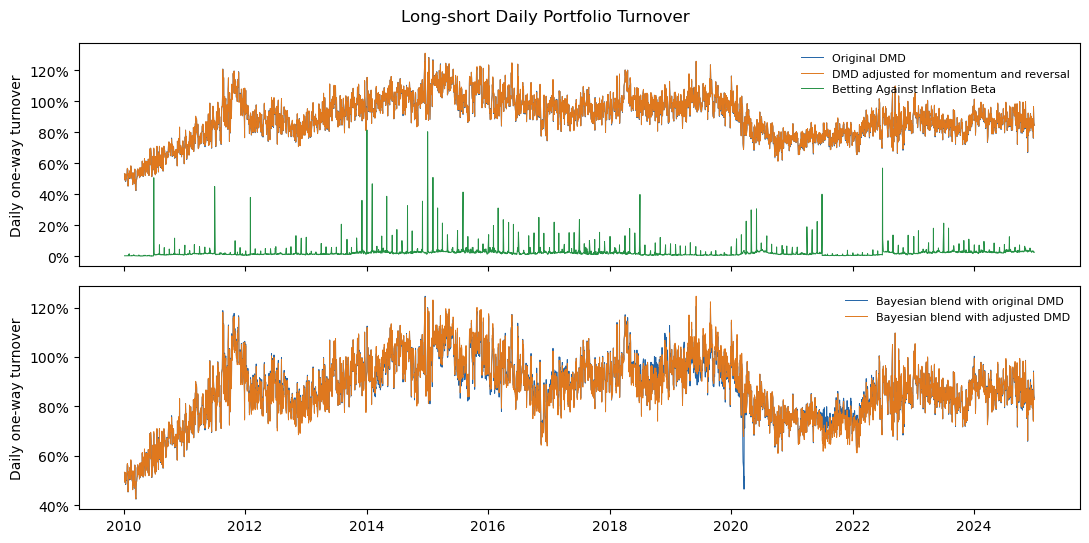

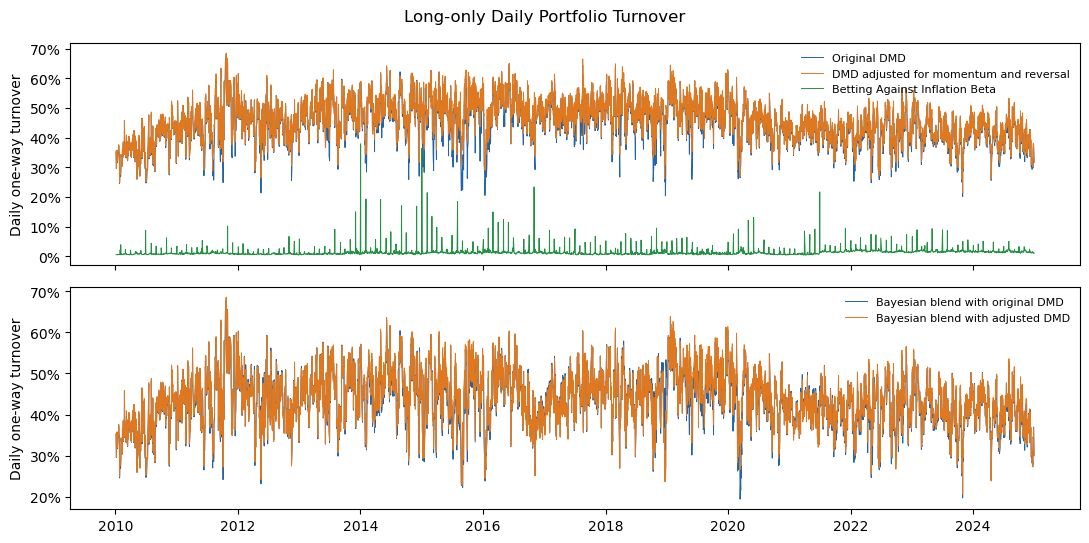

In [2]:
turnover = pd.read_parquet(DATA / 'regular_dmd_turnover.parquet')
turnover['date'] = pd.to_datetime(turnover['date'])
summary = turnover.groupby(['portfolio', 'variant'])['turnover'].agg(['mean', 'median'])
summary = summary.rename(index=LABELS, level='portfolio').rename(index=VARIANTS, level='variant')
summary.columns = ['Mean daily one-way turnover', 'Median daily one-way turnover']
display(summary.style.format('{:.2%}'))

for variant, label in VARIANTS.items():
    fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
    for ax, models in zip(axes, [SIGNALS, BLENDS]):
        for model in models:
            group = turnover.loc[(turnover['portfolio'] == model) & (turnover['variant'] == variant)].sort_values('date')
            ax.plot(group['date'], group['turnover'], label=LABELS[model], color=COLORS[model], linewidth=.7)
        ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.set_ylabel('Daily one-way turnover')
        ax.legend(frameon=False, fontsize=8)
    fig.suptitle(f'{label} Daily Portfolio Turnover')
    fig.tight_layout()
    plt.show()

## 4.2 Test trading-cost sensitivity

For each date with turnover, subtract turnover times the assumed cost rate from the active return. One basis point is 0.01%. The cost rate applies to one-way turnover as defined above. The break-even rate is the gross mean active return divided by mean turnover. The calculation uses the same dates for both means. The scenarios exclude separate borrow and financing costs and do not model the effect of trade size on prices.

In [3]:
matched = returns.merge(turnover, on=['date', 'portfolio', 'variant'], validate='one_to_one')
assert matched.groupby(['portfolio', 'variant']).size().eq(3772).all()
rows = []
for (model, variant), group in matched.groupby(['portfolio', 'variant']):
    active, daily_turnover = group['active_return'], group['turnover']
    row = {'Portfolio': LABELS[model], 'Constraint': VARIANTS[variant],
           'Break-even cost (bp)': 10_000 * active.mean() / daily_turnover.mean()}
    for cost_bp in (0, .25, .50, 1, 2):
        row[f'{cost_bp:g} bp cost'] = 252 * (active - daily_turnover * cost_bp / 10_000).mean()
    rows.append(row)
table = pd.DataFrame(rows).set_index(['Portfolio', 'Constraint'])
display(table.style.format({c: '{:.2f}' if c.startswith('Break-even') else '{:.2%}' for c in table}))

The Bayesian blend with original DMD breaks even at 0.98 basis points per dollar of one-way turnover for long-only and 0.60 for long-short. At 1 basis point, annualized active return falls to −0.02% and −0.88%, respectively, on the dates with turnover data.

## 4.3 Compare drawdown

The top chart in each pair uses wealth relative to the benchmark. The bottom chart uses total portfolio wealth. These charts show the two Bayesian blends.

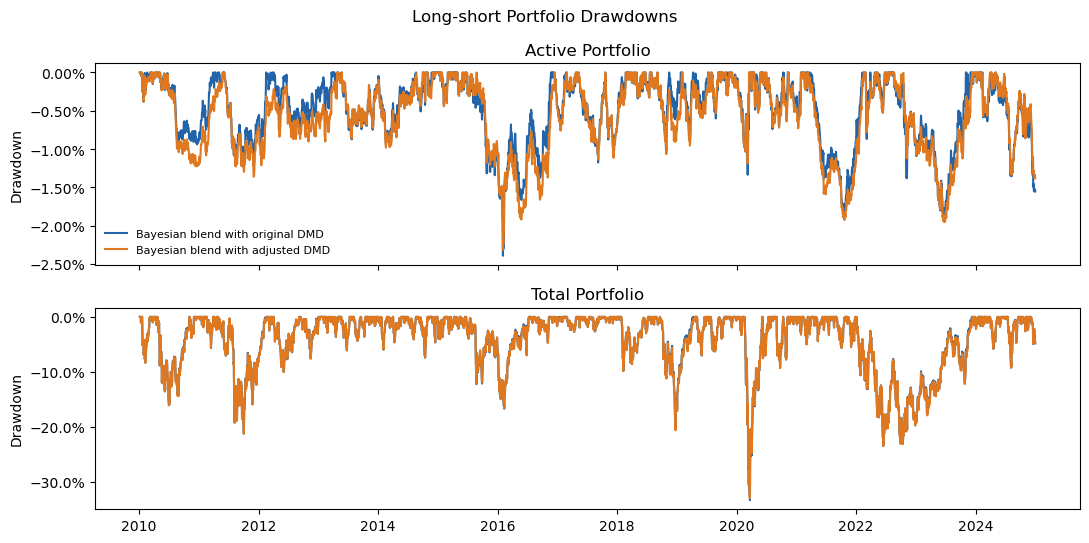

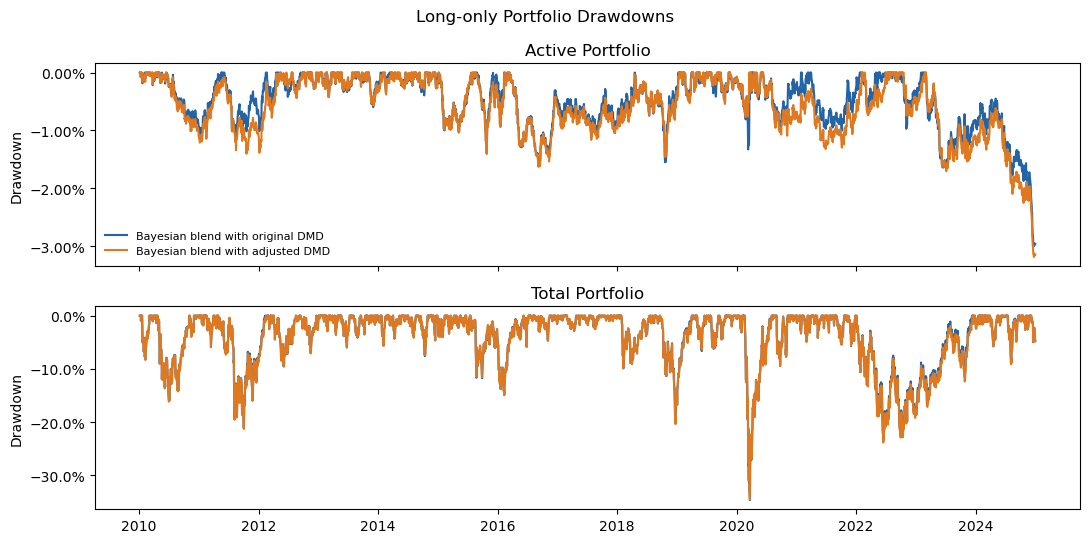

In [4]:
for variant, label in VARIANTS.items():
    fig, axes = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True)
    for ax, relative in zip(axes, [True, False]):
        for model in BLENDS:
            group = returns.loc[(returns['portfolio'] == model) & (returns['variant'] == variant)]
            path = growth(group, relative)
            drawdown = np.expm1(path - np.maximum.accumulate(path))[1:]
            ax.plot(group['return_date'], drawdown, label=LABELS[model], color=COLORS[model])
        ax.set_title('Active Portfolio' if relative else 'Total Portfolio')
        ax.set_ylabel('Drawdown')
        ax.yaxis.set_major_formatter(PercentFormatter(1))
    axes[0].legend(frameon=False, fontsize=8)
    fig.suptitle(f'{label} Portfolio Drawdowns')
    fig.tight_layout()
    plt.show()

## 4.4 Measure active factor exposures

The table gives mean Barra exposures relative to the benchmark. It uses the Barra risk model to measure exposures for both blends. The adjusted DMD score itself uses the separate sf-quant momentum and reversal scores. Factor variance shares use the forecast risk model and include covariance between factors. The shares do not measure how much of the realized return each factor caused.

In [5]:
factors = pd.read_parquet(DATA / 'regular_dmd_factor_exposures.parquet')
keys = ['date', 'portfolio', 'variant']
assert not factors.duplicated([*keys, 'factor']).any()
assert factors.groupby(['portfolio', 'variant'])['date'].nunique().eq(3773).all()
names = {
    'USSLOWL_SIZE': 'Size', 'USSLOWL_MIDCAP': 'Mid-cap',
    'USSLOWL_RESVOL': 'Residual volatility', 'USSLOWL_VALUE': 'Value',
    'USSLOWL_PROFIT': 'Profitability', 'USSLOWL_MOMENTUM': 'Barra momentum',
    'USSLOWL_LTREVRSL': 'Barra long-term reversal', 'USSLOWL_PHARMA': 'Pharmaceuticals',
}
style = (factors.loc[factors['factor'].isin(names)]
    .pivot_table(index='factor', columns=['portfolio', 'variant'], values='active_exposure')
    .loc[list(names)].rename(index=names))
style = style.rename(columns=LABELS, level=0).rename(columns=VARIANTS, level=1)
display(style.style.format('{:+.4f}'))

risk_share = (factors.groupby(keys)['share_of_forecast_variance'].sum()
              .groupby(['portfolio', 'variant']).mean()
              .rename(index=LABELS, level=0).rename(index=VARIANTS, level=1))
display(risk_share.to_frame('Factors’ share of forecast active variance').style.format('{:.2%}'))